# WattIf — ARIMA / SARIMA

Données de Fayfa : `data/daily.csv`, cible `conso_gwh`, en GWh/jour.

Le découpage externe reprend les 90 % d'apprentissage et 10 % de test de Fayfa. Les 56 derniers jours de l'apprentissage sont une validation interne : huit prévisions successives à 7 jours, sans réestimation des paramètres entre les semaines. Le test externe reste réservé à l'évaluation finale, après sélection.

L'EDA de Fayfa a déjà utilisé tout l'apprentissage, y compris cette validation interne : cette validation est donc exploratoire. Le test externe n'entre pas dans le choix des modèles. Les résultats de l'aide IA ne remplacent pas l'interprétation personnelle demandée dans la section 5.


## 1. Environnement
Exécuter cette cellule d'installation uniquement si les bibliothèques manquent. `pmdarima` est nécessaire pour `auto_arima` ; une erreur d'installation doit être résolue avant de conclure la comparaison automatique.

In [1]:
# Décommenter si nécessaire dans Jupyter :
# %pip install -r requirements.txt

In [2]:
from pathlib import Path
import json
import warnings
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera

for package in ['numpy', 'pandas', 'matplotlib', 'scipy', 'statsmodels', 'pmdarima']:
    try:
        print(package, metadata.version(package))
    except metadata.PackageNotFoundError:
        print(package, 'non installé')


numpy 1.26.4
pandas 2.3.3
matplotlib 3.9.4
scipy 1.13.1
statsmodels 0.14.6
pmdarima 2.0.4


## 2. Configuration
Période hebdomadaire : 7 jours. d=1 et D=1 servent à illustrer les graphiques différenciés ; les candidats manuels comprennent aussi d=0 ou D=0. Ils ne sont pas imposés à la recherche automatique.


In [3]:
DATA_PATH = Path('data/daily.csv')
DATE_COL = 'date'         # Colonne du fichier préparé par Fayfa
TARGET_COL = 'conso_gwh'  # Consommation électrique journalière
UNIT = 'GWh / jour'       # Unité documentée par Fayfa
CSV_SEP = ','
CSV_DECIMAL = '.'
DATE_FORMAT = '%Y-%m-%d'
SEASONAL_PERIOD = 7       # Cycle hebdomadaire observé par Fayfa
D_ORDER = 1            # d, à justifier par l'analyse
SEASONAL_D_ORDER = 1   # D, à justifier par l'analyse
HORIZON = 7
ALPHA = 0.05              # Intervalles nominaux à 95 %
OUT = Path('exports')


In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError("Fichier data/daily.csv introuvable : ouvrir le notebook depuis la racine du projet.")
raw = pd.read_csv(DATA_PATH, sep=CSV_SEP, decimal=CSV_DECIMAL)
print('Dimensions :', raw.shape)
print('Colonnes :', raw.columns.tolist())
display(raw.head())


Dimensions : (3896, 16)
Colonnes : ['date', 'conso_gwh', 'temp_moy', 'temp_min', 'temp_max', 'hdd', 'cdd', 'taux_co2', 'nucleaire_gwh', 'gaz_gwh', 'eolien_gwh', 'solaire_gwh', 'ferie', 'jour_semaine', 'temp_interpolee', 'nature']
         date  conso_gwh  temp_moy  temp_min  temp_max     hdd  cdd  taux_co2  nucleaire_gwh  gaz_gwh  eolien_gwh  solaire_gwh  ferie  jour_semaine  temp_interpolee               nature
0  2016-01-01   1290.957     7.260     3.622    10.899  10.740  0.0    32.083       1272.590   53.442      77.688        7.610      1             4                0  Données définitives
1  2016-01-02   1331.506     8.898     6.862    10.932   9.102  0.0    30.604       1257.404   54.714     142.394        5.586      0             5                0  Données définitives
2  2016-01-03   1362.676     7.399     5.075     9.722  10.601  0.0    31.250       1233.225   53.916     128.023        3.958      0             6                0  Données définitives
3  2016-01-04   1546.489  

### Contrôler les données
Le code exige une observation par jour, sans doublon ni valeur manquante. Il ne remplace pas automatiquement les absences par zéro : zéro et donnée absente n'ont pas le même sens. Tout traitement doit être convenu et documenté. Les transformations calculées à partir des données devront être apprises sur l'entraînement seulement.

Estimation 3450 2016-01-01 → 2025-06-11
Validation interne 56 2025-06-12 → 2025-08-06
Test réservé 390 2025-08-07 → 2026-08-31


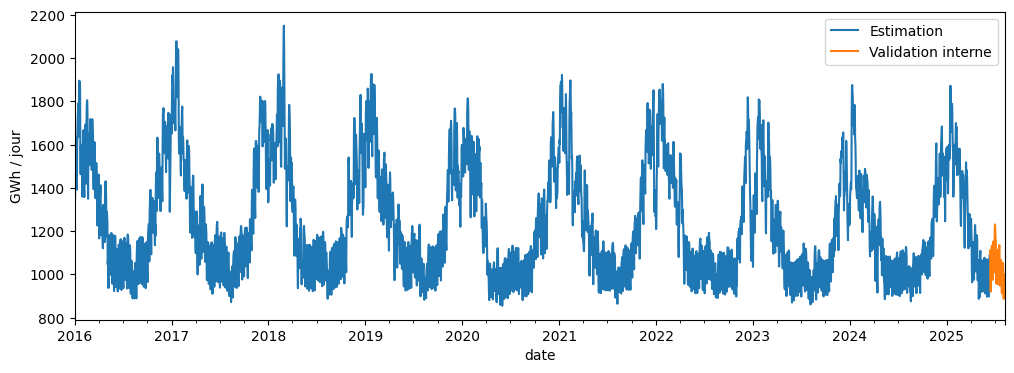

In [5]:
if DATE_COL is None or TARGET_COL is None:
    raise ValueError('Renseigner DATE_COL et TARGET_COL après avoir lu les colonnes.')
data = raw[[DATE_COL, TARGET_COL]].copy()
data[DATE_COL] = pd.to_datetime(data[DATE_COL], format=DATE_FORMAT, errors='raise')
if data[DATE_COL].isna().any():
    raise ValueError('Dates manquantes : demander une correction.')
if not data[DATE_COL].eq(data[DATE_COL].dt.normalize()).all():
    raise ValueError('Présence d’heures : confirmer la règle d’agrégation quotidienne.')
if data[DATE_COL].duplicated().any():
    raise ValueError('Dates dupliquées : confirmer l’agrégation avec Fayfa.')
data[TARGET_COL] = pd.to_numeric(data[TARGET_COL], errors='raise')
y = data.set_index(DATE_COL)[TARGET_COL].sort_index().asfreq('D')
if y.isna().any() or not np.isfinite(y.to_numpy()).all():
    raise ValueError('Jours absents, valeurs manquantes ou infinies : documenter leur traitement avant de continuer.')
if len(y) <= HORIZON + 10:
    raise ValueError('Série trop courte pour ce protocole exploratoire.')
n_train = int(len(y) * 0.9)
development, test = y.iloc[:n_train], y.iloc[n_train:]
VALIDATION_DAYS = 56
train, validation = development.iloc[:-VALIDATION_DAYS], development.iloc[-VALIDATION_DAYS:]
assert train.index[-1] < validation.index[0] < test.index[0]
assert len(validation) % HORIZON == 0
for label, part in [('Estimation', train), ('Validation interne', validation), ('Test réservé', test)]:
    print(label, len(part), part.index[0].date(), '→', part.index[-1].date())
ax = train.plot(figsize=(12, 4), label='Estimation')
validation.plot(ax=ax, label='Validation interne')
# Le test externe n'est pas utilisé pour l'identification des modèles.
ax.set_ylabel(UNIT)
ax.legend()
plt.show()


## 3. Stationnarité, ACF et PACF
Les calculs suivants utilisent uniquement l'échantillon d'estimation interne. Le commentaire de Fayfa ci-dessous porte sur son apprentissage complet : les graphiques recalculés peuvent donc légèrement différer.

ADF : hypothèse nulle de racine unitaire. KPSS avec constante : hypothèse nulle de stationnarité autour d'un niveau. Les p-values ne suffisent pas à imposer d et D ; examiner aussi la saisonnalité et le risque de sur-différenciation.


In [6]:
def stationarity(series):
    a = adfuller(series.dropna(), regression='c', autolag='AIC')
    k = kpss(series.dropna(), regression='c', nlags='auto')
    return pd.DataFrame([
        {'test': 'ADF (constante)', 'statistique': a[0], 'p_value': a[1], 'retards': a[2]},
        {'test': 'KPSS (constante)', 'statistique': k[0], 'p_value': k[1], 'retards': k[2]},
    ])
display(stationarity(train))


cell_10:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

               test  statistique   p_value  retards
0   ADF (constante)    -4.107211  0.000942       30
1  KPSS (constante)     0.341459  0.100000       37


cell_10:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

               test  statistique       p_value  retards
0   ADF (constante)   -18.256452  2.336461e-30       30
1  KPSS (constante)     0.008801  1.000000e-01       16


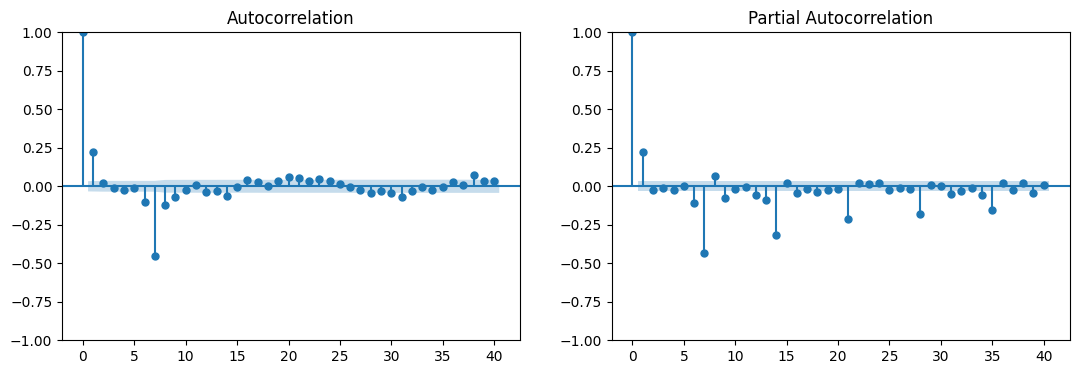

In [7]:
if any(v is None for v in [D_ORDER, SEASONAL_D_ORDER, SEASONAL_PERIOD]):
    raise ValueError('Confirmer d, D et la période saisonnière avant de poursuivre.')
if not isinstance(SEASONAL_PERIOD, int) or SEASONAL_PERIOD < 2:
    raise ValueError('La période saisonnière doit être un entier >= 2.')
if any(not isinstance(v, int) or v < 0 for v in [D_ORDER, SEASONAL_D_ORDER]):
    raise ValueError('d et D doivent être des entiers positifs ou nuls.')
z = train.copy()
for _ in range(SEASONAL_D_ORDER):
    z = z.diff(SEASONAL_PERIOD)
for _ in range(D_ORDER):
    z = z.diff()
z = z.dropna()
if len(z) < 12 or z.nunique() < 2:
    raise ValueError('Trop peu de données exploitables après différenciation.')
display(stationarity(z))
lags = min(40, len(z) // 2 - 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(z, lags=lags, ax=axes[0])
plot_pacf(z, lags=lags, method='ywm', ax=axes[1])
plt.show()


### Lecture des ACF/PACF — aide rédigée avec une IA

Cette lecture porte sur `figures/acf_pacf.png`, produit par Fayfa sur les **3 506 jours d'entraînement**, jusqu'au 6 août 2025. Les valeurs ci-dessous sont des approximations visuelles, pas de nouveaux calculs. Elle ne doit pas être présentée comme ton analyse personnelle rédigée avant consultation d'un LLM.

**Comprendre les axes.** Un retard de 1 compare la consommation avec celle de la veille ; un retard de 7 avec celle du même jour de la semaine précédente. L'ACF mesure leur corrélation ; la PACF mesure le lien restant après prise en compte des retards intermédiaires. La bande bleue représente une incertitude point par point autour de zéro. Le pic au retard zéro est égal à 1 par construction : on ne l'utilise pas pour choisir les ordres.

**1. Série brute.** L'ACF reste élevée et diminue lentement, avec des bosses tous les 7 jours. Cela révèle une forte persistance et un cycle hebdomadaire. La PACF présente notamment un grand pic au retard 1 et un pic négatif vers 8. Une ACF lente ne prouve pas à elle seule une racine unitaire : le cycle annuel peut aussi contribuer à cette forme.

**2. Différence simple : consommation du jour moins celle de la veille.** Les pics ACF aux retards 7, 14, 21, etc. restent élevés (environ 0,7). La différence simple ne suffit donc pas à retirer la structure hebdomadaire. Cela motive une comparaison de modèles saisonniers, sans démontrer à lui seul que D=1 est obligatoire.

**3. Différence simple et saisonnière.** La plupart des corrélations sont beaucoup plus petites. L'ACF présente un pic positif au retard 1 (environ 0,2) et un pic négatif au retard 7 (environ -0,45). Plusieurs autres pics subsistent : il serait incorrect de dire que tous les autres retards sont dans la bande. La PACF décroît globalement aux multiples de 7. Ce motif suggère de tester un terme MA saisonnier Q=1 et une composante non saisonnière de faible ordre.

**Croisement avec les tests de Fayfa.** Sur la série brute, ADF p=0,001 et KPSS p=0,0759 : au seuil de 5 %, ces résultats ne rendent pas d=1 obligatoire. Les recommandations automatiques divergent aussi pour d et D. On teste donc d=1, D=1 comme une hypothèse, avec des variantes d=0 ou D=0. Un pic positif au retard 1 ne suffit pas à exclure toute sur-différenciation, notamment saisonnière.

| Candidat | Pourquoi le tester ? |
|---|---|
| SARIMA(0,1,1)(0,1,1)[7] | MA court et MA hebdomadaire suggérés par l'ACF |
| SARIMA(1,1,0)(0,1,1)[7] | Variante AR au retard 1 |
| SARIMA(1,1,1)(0,1,1)[7] | Combinaison AR/MA, à comparer aux versions plus simples |
| SARIMA(1,1,0)(1,0,1)[7] | Variante sans différence saisonnière |
| SARIMA(1,0,0)(1,0,1)[7] | Variante sans différenciation, vu les tests sur la série brute |
| ARIMA(1,1,0) et ARIMA(0,1,1) | Références sans composante saisonnière explicite |

**Décision provisoire.** Retenir une période de 7 jours et cette petite liste de candidats ; ne pas annoncer un meilleur modèle avant comparaison des prévisions et diagnostics. Le cycle annuel n'est pas explicitement représenté par une unique période 7. Les variantes sans différenciation ne remplacent pas toutes les alternatives possibles, notamment un modèle avec effets du jour de la semaine.

**À reformuler avec tes mots pour comprendre :** pourquoi comparer les retards 1 et 7 ? Pourquoi ces graphiques proposent-ils des candidats sans déterminer un gagnant ?


## 4. Modèles manuels et auto_arima
Les candidats sont motivés par la lecture précédente et incluent des alternatives sans différenciation. La comparaison principale utilise huit semaines de validation interne. À chaque origine, les observations déjà disponibles actualisent l'état du modèle, mais ses paramètres restent fixes : aucune valeur future ne sert à la prévision courante.

La recherche auto_arima se fait uniquement sur l'estimation interne. Elle choisit une spécification par AIC dans un espace borné ; elle ne garantit pas un optimum global. Les AIC/BIC de modèles ayant des différenciations différentes sont à interpréter avec prudence. Les modèles sans différenciation incluent une constante pour représenter le niveau moyen.


In [8]:
CANDIDATES_JUSTIFIED = True  # Activer après harmonisation de la validation et revue de la lecture ci-dessus.
# Les ordres sont explicites : ce sont des hypothèses à comparer, pas des résultats optimaux.
manual_specs = {
    'ARIMA_110': ((1, 1, 0), (0, 0, 0, 0)),
    'ARIMA_011': ((0, 1, 1), (0, 0, 0, 0)),
    'SARIMA_011_011': ((0, 1, 1), (0, 1, 1, 7)),
    'SARIMA_110_011': ((1, 1, 0), (0, 1, 1, 7)),
    'SARIMA_111_011': ((1, 1, 1), (0, 1, 1, 7)),
    'SARIMA_110_101': ((1, 1, 0), (1, 0, 1, 7)),
    'SARIMA_100_101': ((1, 0, 0), (1, 0, 1, 7)),
}
if not CANDIDATES_JUSTIFIED:
    raise ValueError('Adapter/justifier les candidats dans le texte avant de lancer les modèles.')

def fit_model(series, order, seasonal_order):
    return SARIMAX(series, order=order, seasonal_order=seasonal_order,
                   trend=('c' if order[1] + seasonal_order[1] == 0 else 'n'), enforce_stationarity=True,
                   enforce_invertibility=True).fit(disp=False, maxiter=300)

fits, specs, failures = {}, {}, {}
for name, spec in manual_specs.items():
    try:
        result = fit_model(train, *spec)
        if not result.mle_retvals.get('converged', False):
            raise RuntimeError('Optimisation non convergée')
        fits[name], specs[name] = result, spec
    except Exception as exc:
        failures[name] = str(exc)
print('Échecs à examiner :', failures)


Échecs à examiner : {}


In [9]:
# Cette cellule est obligatoire pour achever la comparaison demandée.
from pmdarima import auto_arima
for name, seasonal in [('auto_ARIMA', False), ('auto_SARIMA', True)]:
    auto = auto_arima(
        train, seasonal=seasonal, m=SEASONAL_PERIOD if seasonal else 1,
        d=None, D=None if seasonal else 0,
        start_p=0, start_q=0, max_p=2, max_q=2,
        start_P=0, start_Q=0, max_P=1, max_Q=1,
        with_intercept="auto", information_criterion='aic',
        stepwise=True, suppress_warnings=False, error_action='warn', trace=True,
        maxiter=300,
    )
    spec = (auto.order, auto.seasonal_order)
    # Conserver exactement la constante et les paramètres choisis par auto_arima.
    result = auto.arima_res_
    if not result.mle_retvals.get('converged', False):
        raise RuntimeError(f'{name} : estimation non convergée, à résoudre.')
    fits[name], specs[name] = result, spec
    print(name, spec, 'tendance :', result.model.trend)


/Users/yosragadhgadhi/Desktop/Mini_Projet_Series_Temporelles/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/yosragadhgadhi/Desktop/Mini_Projet_Series_Temporelles/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/yosragadhgadhi/Desktop/Mini_Projet_Series_Temporelles/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/Users/yosragadhgadhi/Desktop/Mini_Projet_Series_Temporelles/.venv/lib/python3.9/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_

In [10]:
def scores(actual, predicted):
    error = np.asarray(actual) - np.asarray(predicted)
    return {'MAE': np.mean(np.abs(error)), 'RMSE': np.sqrt(np.mean(error**2))}

rows, predictions = [], []
for name in list(fits) + ['naif_derniere_valeur', 'naif_saisonnier']:
    state = fits.get(name)
    history = train.copy()
    values = []
    for start in range(0, len(validation), HORIZON):
        block = validation.iloc[start:start + HORIZON]
        if name == 'naif_derniere_valeur':
            pred = np.repeat(history.iloc[-1], len(block))
        elif name == 'naif_saisonnier':
            pred = np.resize(history.iloc[-SEASONAL_PERIOD:].to_numpy(), len(block))
        else:
            pred = state.get_forecast(steps=len(block)).predicted_mean.to_numpy()
        for date, actual, value in zip(block.index, block, pred):
            predictions.append({'modele': name, 'origine': history.index[-1],
                                'date': date, 'observe': actual, 'prevision': value})
        values.extend(pred)
        # Les observations ne sont incorporées qu'après leur prévision.
        if state is not None:
            state = state.append(block.to_numpy(), refit=False)
        history = pd.concat([history, block])
    result = fits.get(name)
    rows.append({'modele': name, **scores(validation, values),
                 'AIC': result.aic if result is not None else np.nan,
                 'BIC': result.bic if result is not None else np.nan})
comparison = pd.DataFrame(rows).set_index('modele').sort_values('RMSE')
display(comparison)
OUT.mkdir(exist_ok=True)
comparison.to_csv(OUT / 'comparaison_validation_interne.csv')
pd.DataFrame(predictions).to_csv(OUT / 'predictions_validation_interne.csv', index=False)
(OUT / 'echecs_modeles.json').write_text(json.dumps(failures, ensure_ascii=False, indent=2))


                            MAE       RMSE           AIC           BIC
modele                                                                
SARIMA_110_011        31.107638  42.967089  35876.304632  35894.736056
SARIMA_110_101        31.144484  43.008954  35957.993730  35982.577088
SARIMA_011_011        30.987908  43.053028  35860.600620  35879.032044
SARIMA_111_011        31.119352  43.373413  35859.821334  35884.396565
SARIMA_100_101        34.379860  47.249570  36058.090166  36088.820813
auto_SARIMA           36.825066  48.104993  37145.477411  37176.206609
naif_saisonnier       44.042107  55.215127           NaN           NaN
auto_ARIMA            59.013547  74.225382  39583.827959  39614.557157
naif_derniere_valeur  67.726054  88.594249           NaN           NaN
ARIMA_110             67.682669  88.917719  40355.586253  40367.877932
ARIMA_011             67.842887  89.211149  40236.046804  40248.338483


## 5. Diagnostics des résidus
Ljung–Box recherche une autocorrélation restante ; Jarque–Bera évalue la normalité ; ARCH-LM recherche une variance conditionnelle variable. Une p-value > 0,05 ne prouve pas l'hypothèse nulle. Une non-normalité ou un effet ARCH invite à discuter la fiabilité des intervalles. Les retards testés et les degrés de liberté doivent figurer dans le rapport.


In [11]:
def diagnose(result, spec):
    order, seasonal = spec
    burn = max(int(result.loglikelihood_burn), order[1] + seasonal[1] * seasonal[3])
    resid = pd.Series(np.asarray(result.resid)[burn:]).dropna()
    df = order[0] + order[2] + seasonal[0] + seasonal[2]
    max_lag = min(len(resid) // 5, 2 * SEASONAL_PERIOD)
    lb_lags = sorted(set(lag for lag in [SEASONAL_PERIOD, max_lag] if df < lag <= max_lag))
    if not lb_lags:
        raise ValueError('Résidus insuffisants pour Ljung–Box avec ces degrés de liberté.')
    lb = acorr_ljungbox(resid, lags=lb_lags, model_df=df, return_df=True)
    jb, jb_p, skew, kurt = jarque_bera(resid)
    arch_lags = min(SEASONAL_PERIOD, len(resid) // 5)
    lm, lm_p, _, _ = het_arch(resid, nlags=arch_lags, ddof=df)
    return lb, {'JB': jb, 'JB_p': jb_p, 'asymetrie': skew, 'kurtosis': kurt,
                'ARCH_LM': lm, 'ARCH_p': lm_p, 'ARCH_retards': arch_lags}

diagnostic_rows = []
for name, result in fits.items():
    print(name, specs[name])
    lb, other = diagnose(result, specs[name])
    display(lb)
    display(pd.Series(other))
    for lag, row in lb.iterrows():
        diagnostic_rows.append({'modele': name, 'retard_LB': int(lag), **row.to_dict(), **other})
pd.DataFrame(diagnostic_rows).to_csv(OUT / 'diagnostics_estimation.csv', index=False)


ARIMA_110 ((1, 1, 0), (0, 0, 0, 0))
       lb_stat  lb_pvalue
7   2851.58652        0.0
14  5557.07519        0.0
JB               2.891200e+02
JB_p             1.653484e-63
asymetrie        6.178955e-01
kurtosis         3.696185e+00
ARCH_LM          1.382155e+03
ARCH_p          2.803836e-294
ARCH_retards     7.000000e+00
ARIMA_011 ((0, 1, 1), (0, 0, 0, 0))
        lb_stat  lb_pvalue
7   2508.711881        0.0
14  4900.443771        0.0
JB               3.068233e+02
JB_p             2.366879e-67
asymetrie        6.483817e-01
kurtosis         3.673384e+00
ARCH_LM          1.427254e+03
ARCH_p          4.891629e-304
ARCH_retards     7.000000e+00
SARIMA_011_011 ((0, 1, 1), (0, 1, 1, 7))
       lb_stat     lb_pvalue
7    70.578039  7.768243e-14
14  109.539090  7.381408e-18
JB              3.137807e+03
JB_p            0.000000e+00
asymetrie       3.372540e-02
kurtosis        7.677008e+00
ARCH_LM         2.996087e+02
ARCH_p          7.333338e-61
ARCH_retards    7.000000e+00
SARIMA_110_011 ((1

## Résultats de la première comparaison — aide IA à discuter

Calculs exécutés sur les données réelles. Estimation : 3 450 jours jusqu'au 11 juin 2025 ; validation : huit semaines du 12 juin au 6 août 2025. Les 390 jours de test externe restent réservés.

| Modèle | MAE (GWh/jour) | RMSE (GWh/jour) |
|---|---:|---:|
| SARIMA(1,1,0)(0,1,1)[7] | 31,11 | 42,97 |
| SARIMA(1,1,0)(1,0,1)[7] | 31,14 | 43,01 |
| SARIMA(0,1,1)(0,1,1)[7] | 30,99 | 43,05 |
| auto_SARIMA : (2,1,1)(1,0,0)[7] | 36,83 | 48,10 |
| Naïf saisonnier | 44,04 | 55,22 |
| auto_ARIMA : (2,1,2) | 59,01 | 74,23 |
| Dernière valeur | 67,73 | 88,59 |

**Interprétation provisoire.** La plus petite RMSE revient à SARIMA(1,1,0)(0,1,1)[7], mais les trois premiers modèles sont presque à égalité. La plus petite MAE revient à SARIMA(0,1,1)(0,1,1)[7]. La variante D=0 est compétitive : D=1 n'est donc pas un choix acquis. La recherche automatique minimise un critère d'information sur l'estimation, pas l'erreur de validation ; elle ne gagne pas nécessairement sur les prévisions.

**Diagnostics.** Pour tous les modèles estimés, les p-values Ljung–Box aux retards 7 et 14 sont inférieures à 0,05. Jarque–Bera et ARCH-LM rejettent aussi leurs hypothèses nulles. Les résidus gardent une structure temporelle, ne sont pas compatibles avec la normalité selon ce test et montrent des effets ARCH. Les p-values affichées à 0 sont des limites numériques d'affichage/calcul, pas des probabilités exactement nulles démontrées.

**Conséquence.** Aucun modèle n'est encore déclaré validé. Examiner les résidus et les effets hebdomadaires/annuels non représentés avant de figer le choix. La validation ne couvre que huit semaines d'été et l'EDA initiale de Fayfa l'avait déjà consultée : ces résultats restent exploratoires. Une amélioration de RMSE sur cette période ne garantit pas un gain sur toute l'année. Ne pas utiliser le test externe pour ajuster les ordres.

Les tableaux complets sont dans `exports/comparaison_validation_interne.csv`, `exports/predictions_validation_interne.csv` et `exports/diagnostics_estimation.csv`. L'analyse personnelle de la section 5 reste à rédiger par l'étudiante ; ce résumé est une assistance IA.


## 6. Finalisation : compléter les candidats, figer le choix, évaluer le test

Les diagnostics précédents motivent quatre variantes supplémentaires à petits ordres. Cette adaptation réutilise la validation interne : elle reste exploratoire. Le choix minimise la RMSE interne parmi les modèles ARIMA/SARIMA convergés ; les références naïves restent visibles. Il est enregistré **avant** l'évaluation du test externe, puis conservé même si les résultats du test sont décevants.

Le test externe contient 390 jours : 55 blocs de 7 jours et un dernier bloc de 5 jours. À chaque origine, les prévisions sont émises avant d'incorporer les observations du bloc. Les paramètres ne sont pas réestimés entre les blocs. Les métriques globales portent sur les horizons 1 à 7 ; un fichier distinct présente chaque horizon. Les intervalles sont nominaux à 95 %, conditionnels au modèle.

Le code détaillé et commenté est dans `scripts/finalisation.py`. Les diagnostics défavorables seront rapportés : terminer une comparaison ne signifie pas que toutes les hypothèses du modèle sont vérifiées.


In [12]:
from scripts.finalisation import finaliser
resultats = finaliser(y, train, validation, development, test, fits, specs, comparison)
display(resultats['comparaison'])
display(resultats['scores_test'])
display(resultats['diagnostics_finaux'])
display(resultats['previsions'])


Traceback (most recent call last):
  File "/Users/yosragadhgadhi/Desktop/Mini_Projet_Series_Temporelles/scripts/executer_comparaison.py", line 35, in <module>
    exec(compile(source,f'cell_{i}','exec'),env)
  File "cell_21", line 1, in <module>
ModuleNotFoundError: No module named 'scripts'


## 7. Figures finales et livraison

Le modèle est réajusté sur toutes les observations après évaluation du test. Les prévisions concernent les **sept jours suivant le 31 août 2026**, pas les sept jours suivant la date de rédaction du rapport.

Exports : `exports/previsions_7j.csv`, `exports/metadonnees_previsions.json`, `exports/scores_test.csv`, `exports/scores_test_par_horizon.csv`, `exports/diagnostics_modele_retenu.csv`.


In [ ]:
from IPython.display import Image, display
for fichier in ['previsions_7j.png', 'diagnostics_finaux.png', 'test_externe.png']:
    display(Image(filename=str(Path('figures/arima_sarima') / fichier)))


## 8. Rapport, analyse LLM et annexe

L'étudiante a indiqué dans cette conversation qu'elle n'avait pas rédigé d'interprétation personnelle avant l'aide IA. Cette condition chronologique ne peut pas être reconstituée honnêtement après coup. Les livrables distinguent donc le bilan statistique calculé, la vulgarisation assistée et la réflexion personnelle à rédiger maintenant.

Voir `rapport/section_3_1_arima_sarima.md`, `rapport/section_5_analyse_llm.md`, et `rapport/annexe_llm/`. Les prompts de restitution et les réponses intégrales sont conservés avec leur provenance réelle. Aucun échange avec un autre modèle ni avis personnel antérieur n'est inventé.
